# Homework 7 — Problems 1–3
Name: Hao Pang; ID: 6495868529; Course: DSCI 552

## 1. Multi-class and Multi-label Classification Using Support Vector Machines
### (a) Data and train/test split
I exclude RecordID and use 22 MFCC features to predict Family, Genus,
and Species. I randomly split the records into 70% training and 30% test
sets using seed 42. The test set is reserved for final evaluation.


In [1]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("Anuran Calls (MFCCs)")
df = pd.read_csv(DATA_PATH / "Frogs_MFCCs.csv")

print("Data shape:", df.shape)


Data shape: (7195, 26)


In [2]:
from sklearn.model_selection import train_test_split

SEED = 42
label_cols = ["Family", "Genus", "Species"]

X = df.drop(columns=label_cols + ["RecordID"])
y = df[label_cols]

print("Missing values:", df.isna().sum().sum())
print("Number of classes:")
print(y.nunique())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED
)

print("\nTraining features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)

Missing values: 0
Number of classes:
Family      4
Genus       8
Species    10
dtype: int64

Training features: (5036, 22)
Test features: (2159, 22)
Training labels: (5036, 3)
Test labels: (2159, 3)


### (b)(i) Evaluation metrics
For $n$ observations and three categorical targets, let
$e_{ij}=\mathbf{1}(y_{ij}\ne\hat y_{ij})$.

- **Exact match:** $\frac{1}{n}\sum_i\mathbf{1}(\sum_{j=1}^3e_{ij}=0)$;
  all three labels must be correct.
- **Hamming loss:** $\frac{1}{3n}\sum_i\sum_{j=1}^3e_{ij}$.
- **Hamming score:** $1-\text{Hamming loss}$, the fraction of correct target entries.
- **Average Hamming distance:** $\frac{1}{n}\sum_i\sum_{j=1}^3e_{ij}$,
  the number of incorrect targets per observation.

Higher exact match and Hamming score are better; lower loss and distance
are better. I compare the three categorical target positions directly.
Here, “Hamming score” uses label-wise accuracy, rather than set-based
Jaccard similarity or accuracy across one-hot indicator columns.

Reference: [scikit-learn: Hamming loss](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.hamming_loss.html).


In [3]:
import numpy as np

def evaluate_predictions(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    correct = y_true == y_pred

    return {
        "Exact match": correct.all(axis=1).mean(),
        "Hamming score": correct.mean(),
        "Hamming loss": (~correct).mean(),
        "Average Hamming distance": (~correct).sum(axis=1).mean()
    }

### (b)(ii) Gaussian-kernel SVMs
I train one classifier per target, with one-versus-rest classification
within each target. A pipeline standardizes features separately within
each cross-validation training fold.

I select $C\in\{0.1,1,10,100\}$ and $\gamma\in\{0.01,0.1,1,10\}$
using 10-fold stratified cross-validation and target-wise accuracy.
For the Gaussian kernel, $\gamma=1/(2\sigma^2)$.
Reported parameters are the best among this finite grid; each selected
model is refitted on the full training set before test prediction.

The raw MFCC features already lie in [-1, 1], as the assignment notes.
I therefore report only the standardized version; standardization
keeps the RBF distance from being dominated by any one coefficient.


In [4]:
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

param_grid = {
    "svm__estimator__C": [0.1, 1, 10, 100],
    "svm__estimator__gamma": [0.01, 0.1, 1, 10]
}

rbf_models = {}
rbf_pred = pd.DataFrame(index=y_test.index)
rbf_rows = []

for label in label_cols:

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", OneVsRestClassifier(SVC(kernel="rbf")))
    ])

    search = GridSearchCV(
        model,
        param_grid,
        scoring="accuracy",
        cv=cv,
        n_jobs=2
    )
    search.fit(X_train, y_train[label])

    rbf_models[label] = search.best_estimator_
    rbf_pred[label] = search.predict(X_test)

    rbf_rows.append({
        "Label": label,
        "Best C": search.best_params_["svm__estimator__C"],
        "Best gamma": search.best_params_["svm__estimator__gamma"],
        "CV accuracy": search.best_score_,
        "Test accuracy": (
            rbf_pred[label] == y_test[label]
        ).mean()
    })


rbf_results = pd.DataFrame(rbf_rows).set_index("Label")
rbf_results.round(4)


,Best C,Best gamma,CV accuracy,Test accuracy
Label,,,,
Family,10,0.1,0.9905,0.9935
Genus,10,0.1,0.9891,0.9884
Species,10,0.1,0.9889,0.9880


In [5]:
model_scores = {
    "RBF SVM": evaluate_predictions(y_test, rbf_pred)
}


All three targets selected C = 10 and gamma = 0.1. Test accuracies
were 0.9935 (Family), 0.9884 (Genus), and 0.9880 (Species).
The joint exact match was 0.9866 and Hamming loss was approximately 0.0100.


### (b)(iii) L1-penalized linear SVMs

I train a separate L1-penalized linear SVM for each target.
Features are standardized within each cross-validation fold.
I select C from 0.001, 0.01, 0.1, 1, 10, and 100 using
10-fold stratified cross-validation.

In [6]:
from sklearn.svm import LinearSVC

l1_grid = {
    "svm__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

l1_models = {}
l1_pred = pd.DataFrame(index=y_test.index)
l1_rows = []

for label in label_cols:

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            multi_class="ovr",
            max_iter=100000,
            random_state=SEED
        ))
    ])

    search = GridSearchCV(
        model,
        l1_grid,
        scoring="accuracy",
        cv=cv,
        n_jobs=2
    )
    search.fit(X_train, y_train[label])

    l1_models[label] = search.best_estimator_
    l1_pred[label] = search.predict(X_test)

    l1_rows.append({
        "Label": label,
        "Best C": search.best_params_["svm__C"],
        "CV accuracy": search.best_score_,
        "Test accuracy": (
            l1_pred[label] == y_test[label]
        ).mean()
    })


l1_results = pd.DataFrame(l1_rows).set_index("Label")
l1_results.round(4)


,Best C,CV accuracy,Test accuracy
Label,,,
Family,10,0.9412,0.9282
Genus,100,0.9516,0.9416
Species,10,0.9607,0.9592


In [7]:
model_scores["L1 SVM"] = evaluate_predictions(y_test, l1_pred)


In [8]:
# Check whether Genus improves beyond the grid's upper endpoint (C = 100).
genus_search = GridSearchCV(
    Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            multi_class="ovr",
            max_iter=100000,
            random_state=SEED
        ))
    ]),
    {"svm__C": [10, 100, 1000, 10000]},
    scoring="accuracy",
    cv=cv,
    n_jobs=2
)
genus_search.fit(X_train, y_train["Genus"])

pd.Series(
    genus_search.cv_results_["mean_test_score"],
    index=pd.Index([10, 100, 1000, 10000], name="C"),
    name="Genus CV accuracy"
).round(4)

C
10       0.9516
100      0.9516
1000     0.9517
10000    0.9517
Name: Genus CV accuracy, dtype: float64

The best tested C values were 10, 100, and 10 for Family, Genus,
and Species. Genus selected the grid's upper endpoint. Extending the grid to
C = 1,000 and 10,000 changed its CV accuracy only from 0.9516 to
0.9517, so the accuracy had already plateaued and the conclusion
does not depend on the grid's upper limit.

Exact match was 0.9125 and Hamming loss was 0.0570, worse than the
RBF model. Nonlinear boundaries may help, although the models also
differ in their regularization.


### (b)(iv) L1-penalized SVMs with SMOTE

The training data are imbalanced. For example, Family counts range
from 41 to 3,073.

For each target, I apply SMOTE after standardization to balance
the classes in the training portion of each cross-validation fold.
Validation and test data are not resampled.

I use an L1-penalized linear SVM and select C using the same
candidate values and 10-fold cross-validation as before.

In [9]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline


In [10]:
smote_models = {}
smote_pred = pd.DataFrame(index=y_test.index)
smote_rows = []

for label in label_cols:

    model = ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=SEED, k_neighbors=5)),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            multi_class="ovr",
            max_iter=100000,
            random_state=SEED
        ))
    ])

    search = GridSearchCV(
        model,
        l1_grid,
        scoring="accuracy",
        cv=cv,
        n_jobs=2
    )
    search.fit(X_train, y_train[label])

    smote_models[label] = search.best_estimator_
    smote_pred[label] = search.predict(X_test)

    smote_rows.append({
        "Label": label,
        "Best C": search.best_params_["svm__C"],
        "CV accuracy": search.best_score_,
        "Test accuracy": (
            smote_pred[label] == y_test[label]
        ).mean()
    })


smote_results = pd.DataFrame(smote_rows).set_index("Label")
smote_results.round(4)


,Best C,CV accuracy,Test accuracy
Label,,,
Family,10,0.9232,0.9092
Genus,1,0.9128,0.9023
Species,10,0.9581,0.9579


In [11]:
model_scores["L1 SVM + SMOTE"] = evaluate_predictions(
    y_test, smote_pred
)

pd.DataFrame.from_dict(model_scores, orient="index").round(4)

,Exact match,Hamming score,Hamming loss,Average Hamming distance
RBF SVM,0.9866,0.9900,0.0100,0.0301
L1 SVM,0.9125,0.9430,0.0570,0.1709
L1 SVM + SMOTE,0.8536,0.9231,0.0769,0.2307


In [12]:
from sklearn.metrics import balanced_accuracy_score

balance_rows = []

for label in label_cols:
    balance_rows.append({
        "Label": label,
        "L1 SVM": balanced_accuracy_score(
            y_test[label], l1_pred[label]
        ),
        "L1 SVM + SMOTE": balanced_accuracy_score(
            y_test[label], smote_pred[label]
        )
    })

pd.DataFrame(balance_rows).set_index("Label").round(4)

,L1 SVM,L1 SVM + SMOTE
Label,,
Family,0.6902,0.9131
Genus,0.7690,0.9162
Species,0.8948,0.9278


SMOTE reduced exact match from 0.9125 to 0.8536 and increased
Hamming loss from 0.0570 to 0.0769. However, balanced accuracy
increased for all three targets: from 0.6902 to 0.9131 for Family,
0.7690 to 0.9162 for Genus, and 0.8948 to 0.9278 for Species.

Thus, SMOTE improved average recall across classes at the cost
of overall predictive accuracy. Among the three methods, the
RBF SVM achieved the highest exact match and lowest Hamming loss.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Select the number of clusters

I use all 7,195 samples and the 22 original MFCC features,
excluding RecordID and the three target labels.

I select k by maximizing the Calinski–Harabasz score.
The search covers k = 2, ..., 50 because the CH score is
undefined for k = 1. Each K-means fit uses 10 initializations.
This selection will be repeated in each of the 50 Monte Carlo runs.

In [13]:
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
from threadpoolctl import threadpool_limits

X_cluster = X.to_numpy()

def select_kmeans(seed):
    best_score = -np.inf
    best_model = None
    rows = []

    with threadpool_limits(limits=1):
        for k in range(2, 51):
            model = KMeans(
                n_clusters=k,
                n_init=10,
                random_state=seed
            )
            clusters = model.fit_predict(X_cluster)
            score = calinski_harabasz_score(X_cluster, clusters)
            rows.append({"k": k, "CH score": score})

            if score > best_score:
                best_score = score
                best_model = model

    return best_model, pd.DataFrame(rows)

pilot_model, pilot_ch = select_kmeans(SEED)

print("Selected k:", pilot_model.n_clusters)

pilot_ch.sort_values("CH score", ascending=False).head().round(2)


Selected k: 2


,k,CH score
0,2,3680.74
1,3,3157.64
2,4,2756.47
3,5,2628.97
4,6,2390.21


### (b) Assign majority labels to each cluster

For each cluster, I find the most frequent Family, Genus, and Species
separately. These three majority labels are assigned to every sample
in that cluster. Ties are resolved by taking the first sorted mode.

### (c) Evaluate the assigned labels

I compare the cluster-assigned labels with the true labels using
average Hamming distance, Hamming score, and Hamming loss.
These are descriptive clustering results on the full dataset,
rather than held-out test results.

In [14]:
def assign_cluster_labels(clusters):
    predictions = pd.DataFrame(
        index=y.index, columns=label_cols
    )
    rows = []

    for cluster in np.unique(clusters):
        mask = clusters == cluster
        majority = y.loc[mask, label_cols].mode().iloc[0]

        predictions.loc[mask, label_cols] = majority.to_numpy()

        rows.append({
            "Cluster": cluster,
            "Size": int(mask.sum()),
            **majority.to_dict()
        })

    majority_table = pd.DataFrame(rows).set_index("Cluster")
    return predictions, majority_table

pilot_pred, pilot_majority = assign_cluster_labels(
    pilot_model.labels_
)

pilot_majority

,Size,Family,Genus,Species
Cluster,,,,
0,3598,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,3597,Hylidae,Hypsiboas,HypsiboasCordobae


In [15]:
pilot_scores = evaluate_predictions(y, pilot_pred)


### Monte Carlo simulation

I repeat the complete procedure 50 times using random seeds
42 through 91. Each run selects k using the CH score and assigns
majority labels separately for Family, Genus, and Species.

I report the mean and sample standard deviation of the Hamming
metrics across the 50 runs. The pilot run is included as the first run.

In [16]:
mc_rows = [{
    "Run": 1,
    "Seed": SEED,
    "Selected k": pilot_model.n_clusters,
    **pilot_scores
}]


for run in range(2, 51):
    seed = SEED + run - 1
    model, _ = select_kmeans(seed)
    predictions, _ = assign_cluster_labels(model.labels_)
    scores = evaluate_predictions(y, predictions)

    mc_rows.append({
        "Run": run,
        "Seed": seed,
        "Selected k": model.n_clusters,
        **scores
    })

mc_results = pd.DataFrame(mc_rows)

print("Finished all 50 runs.")


Finished all 50 runs.


In [17]:
metrics = [
    "Average Hamming distance",
    "Hamming score",
    "Hamming loss"
]

mc_summary = pd.DataFrame({
    "Mean": mc_results[metrics].mean(),
    "Standard deviation": mc_results[metrics].std(ddof=1)
})

display(mc_summary.round(6))

print("\nSelected k frequencies:")
print(mc_results["Selected k"].value_counts().sort_index())

,Mean,Standard deviation
Average Hamming distance,0.895622,0.0
Hamming score,0.701459,0.0
Hamming loss,0.298541,0.0



Selected k frequencies:
Selected k
2    50
Name: count, dtype: int64


All 50 runs selected k = 2. The mean Hamming distance, score, and loss
were 0.895622, 0.701459, and 0.298541; each sample standard deviation
was exactly zero, because every run gave identical Hamming metrics.
Thus, these evaluation metrics were stable across seeds. About 29.85% of target entries were incorrect.
The CH score generally decreased as k increased, so it selected the
smallest candidate, k = 2. The two-cluster solution therefore cannot
recover the finer target categories: with only two clusters, at most
two of the four families, eight genera, or ten species can be assigned.
These full-data clustering metrics are not directly comparable to the
held-out supervised test results in Problem 1.


## 3. ISLR 12.6.2

### (a) Complete linkage

Observations 1 and 2 merge first at height 0.30.

The distances from {1, 2} to observations 3 and 4 are
max(0.40, 0.50) = 0.50 and max(0.70, 0.80) = 0.80.
Since d(3, 4) = 0.45 is the smallest remaining dissimilarity,
observations 3 and 4 merge next at height 0.45.

Finally, {1, 2} and {3, 4} merge at height
max(0.40, 0.70, 0.50, 0.80) = 0.80.

### (b) Single linkage

Observations 1 and 2 merge first at height 0.30.

The distances from {1, 2} to observations 3 and 4 are
min(0.40, 0.50) = 0.40 and min(0.70, 0.80) = 0.70.
Therefore, observation 3 joins {1, 2} at height 0.40.

Finally, observation 4 joins {1, 2, 3} at height
min(0.70, 0.80, 0.45) = 0.45.

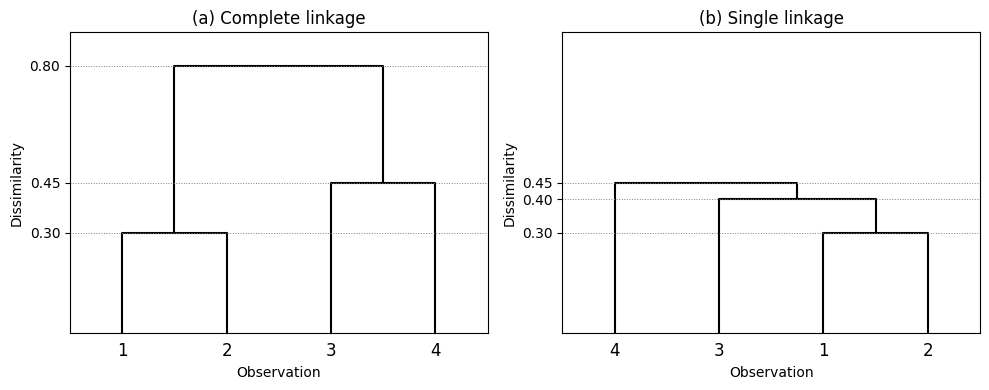

In [18]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

D = np.array([
    [0.00, 0.30, 0.40, 0.70],
    [0.30, 0.00, 0.50, 0.80],
    [0.40, 0.50, 0.00, 0.45],
    [0.70, 0.80, 0.45, 0.00]
])

distances = squareform(D)
Z_complete = linkage(distances, method="complete")
Z_single = linkage(distances, method="single")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, Z, title in zip(
    axes,
    [Z_complete, Z_single],
    ["(a) Complete linkage", "(b) Single linkage"]
):
    dendrogram(
        Z,
        labels=["1", "2", "3", "4"],
        ax=ax,
        color_threshold=0,
        above_threshold_color="black"
    )
    for height in Z[:, 2]:
        ax.axhline(
            height, color="gray", linestyle=":", linewidth=0.7
        )
    ax.set_title(title)
    ax.set_xlabel("Observation")
    ax.set_ylabel("Dissimilarity")
    ax.set_yticks(sorted(set(Z[:, 2])))
    ax.set_ylim(0, 0.9)

plt.tight_layout()
plt.show()

### (c) Two clusters from complete linkage

Cutting the complete-linkage dendrogram between heights 0.45 and
0.80 gives two clusters: {1, 2} and {3, 4}.

### (d) Two clusters from single linkage

Cutting the single-linkage dendrogram between heights 0.40 and
0.45 gives two clusters: {1, 2, 3} and {4}.

### (e) An equivalent dendrogram

Swapping leaves 1 and 2 gives the leaf order 2, 1, 3, 4.
This preserves all cluster memberships and merge heights:
1 and 2 merge at 0.30, 3 and 4 merge at 0.45, and the two
clusters merge at 0.80. Therefore, the dendrogram is equivalent
to the one in part (a).

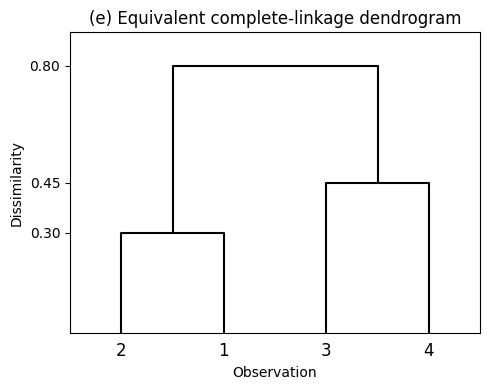

In [19]:
Z_equivalent = Z_complete.copy()
Z_equivalent[0, [0, 1]] = Z_equivalent[0, [1, 0]]

fig, ax = plt.subplots(figsize=(5, 4))

dendrogram(
    Z_equivalent,
    labels=["1", "2", "3", "4"],
    ax=ax,
    color_threshold=0,
    above_threshold_color="black"
)

ax.set_title("(e) Equivalent complete-linkage dendrogram")
ax.set_xlabel("Observation")
ax.set_ylabel("Dissimilarity")
ax.set_yticks([0.30, 0.45, 0.80])
ax.set_ylim(0, 0.9)

plt.tight_layout()
plt.show()

## 4. Extra Practice
Solutions to the remaining exercises in ISLR Section 12.6 are provided
in the separate notebook `Pang_Hao_HW7_Extra.ipynb`.
